# NB07: Extensions, Monitoring, and Utils Public API Walkthrough

This notebook covers RELIC's runtime support layer. You will learn:

1. How `relic.extensions` scaffolds, discovers and validates a user extension (a Functor package with a `relic_extension.yaml` manifest)
2. What `relic.monitoring` records: Prometheus metrics of the REST API (requests, latency, authentication failures, exceptions)
3. How `relic.utils` gives access to the physical-constant and time-constant SSOT and to tensor helpers
4. How the device policy (`relic.core.device_policy`), the feature flags (`relic.core.feature_flags`) and the service registry (`relic.core.service_registry`) behave

**Prerequisites:** NB01-NB06.

**Architecture Reference:** `docs/source/architecture_overview.md`, Section 4.4.2 (Device Management Policy),
Section 6.4 (Physical Constants, Units, and Time SSOT) and Section 12.7 (Loading an External or User Extension).

## Architecture Anchor

This notebook is aligned with `docs\source\architecture_overview.md` and the relevant theory/API pages under `docs\source`.
All computations below are intended to use actual RELIC functors, the actual simulator or orchestration layer, and real validation pathways rather than notebook-defined pseudo-process equations.


### What This Notebook Computes

The support packages contain no scientific process equations. The notebook computes two
bookkeeping ratios from their outputs:

$$
\text{validation\_pass\_rate} = \frac{n_{\text{valid}}}{\max(1,\, n_{\text{discovered}})}
\qquad
\text{issue\_fraction} = \frac{n_{\text{auth failures}} + n_{\text{exceptions}}}{\max(1,\, n_{\text{recorded events}})}
$$

`relic.monitoring` exports only Prometheus metric functions for the REST API
(`record_api_request`, `record_api_auth_failure`, `record_api_exception`,
`export_prometheus_metrics`); it does not monitor a simulation. Simulation diagnostics
belong to their owners: the adaptive step-size metric to
`relic.core.simulator.execution_loop._compute_error_norm` (NB12), the conservation
ledgers and `clip_loss` to `StateManager` (NB11), and domain budgets and the invariant
drift $\left(\sum_j c_j F_j\right)\Delta t$ of `ConservationGuardian.compute_invariant_drift`
(`relic.validation.conservation_guardian`, NB29).

## Setup and Imports

Import the extension, monitoring and utility APIs used below (`relic.extensions`,
`relic.monitoring`, `relic.utils`).

In [1]:
from __future__ import annotations

# Windows: new asyncio event loops use the selector loop (the default is the proactor loop).
import asyncio
if hasattr(asyncio, "WindowsSelectorEventLoopPolicy"):
    asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())

# --- Environment Guard (prevent OpenMP duplicate lib crash) ---
import os, sys
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import json
import sys
from pathlib import Path

DEFAULT_PROJECT_ROOT = Path(os.environ.get("RELIC_PROJECT_ROOT", Path.cwd())).resolve()

def locate_project_root() -> Path:
    candidates = [
        Path.cwd(),
        Path.cwd().parent,
        Path.cwd().parent.parent,
        DEFAULT_PROJECT_ROOT,
    ]
    for candidate in candidates:
        candidate = candidate.resolve()
        if (candidate / "relic").exists() and (candidate / "tutorial").exists():
            return candidate
    raise RuntimeError("Project root not found from current working directory")

PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from relic.extensions import discover_extensions, validate_extension, get_loaded_extensions
from relic.monitoring import (
    export_prometheus_metrics,
    record_api_auth_failure,
    record_api_exception,
    record_api_request,
)
from relic.utils.physical_constants import get_physical_constant
from relic.utils.time_constants import get_time_constants
from relic.utils.tensor_ops import to_tensor

OUTPUT_DIR = PROJECT_ROOT / "tutorial" / "primary" / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SUMMARY_PATH = OUTPUT_DIR / "07_extensions_monitoring_utils_summary.json"
EXTENSION_DIR = OUTPUT_DIR / "extension_demo"

print("[OK] project_root =", PROJECT_ROOT)
print("[OK] output_dir =", OUTPUT_DIR)
print("[OK] extension_dir =", EXTENSION_DIR)


[OK] project_root = <RELIC_ROOT>
[OK] output_dir = tutorial\primary\output
[OK] extension_dir = tutorial\primary\output\extension_demo


## Extension Discovery and Validation

`relic.extensions` loads user Functor packages. An extension root holds a
`relic_extension.yaml` manifest that names each Functor class, its bridge and its
parameter files and a required `execution_group`. Scaffolding requires both `--bridge` and `--execution-group`. The next cell creates such a root with the scaffold command of
`relic.extensions.cli` (`python -m relic.extensions.cli scaffold ...`, called here as
`extensions_cli_main([...])`) when it does not exist yet, discovers it with
`discover_extensions(extra_dirs=[...])` (entry points and `RELIC_EXTENSION_DIRS` are
switched off here) and checks it with `validate_extension()`. Validation imports each
declared class and checks the bridge inheritance, the `forward` signature, the
instantiation, the `FunctorMetadata`, `get_dependencies()` and the declared parameter
files. It does not load the extension, so `get_loaded_extensions()` stays empty.

In [2]:
# References:
# - relic/extensions/README.md.
# - relic/extensions/discovery.py and relic/extensions/validator.py.
# Mathematical expression:
# - validation_pass_rate = n_valid / max(1, n_discovered)
# Parameter meanings:
# - n_discovered: number of extension roots discovered from the target directory.
# - n_valid: number of discovered extensions that pass contract validation.
# - extension_root: directory containing relic_extension.yaml and extension source files.

from relic.extensions.cli import main as extensions_cli_main

if not (EXTENSION_DIR / "relic_extension.yaml").exists():
    scaffold_exit_code = extensions_cli_main(
        [
            "scaffold",
            "tutorial_demo_extension",
            "--bridge",
            "biological_process",
            "--execution-group",
            "medium",
            "--output",
            str(EXTENSION_DIR),
        ]
    )
    assert scaffold_exit_code == 0, "Extension scaffold CLI returned a non-zero status."

extension_infos = discover_extensions(
    extra_dirs=[EXTENSION_DIR],
    use_entry_points=False,
    use_env_dirs=False,
)

valid_count = 0
validation_probe = None
if extension_infos:
    probe = validate_extension(extension_infos[0])
    valid_count = 1 if probe.valid else 0
    validation_probe = {
        "name": extension_infos[0].name,
        "valid": bool(probe.valid),
        "error_count": len(probe.errors),
        "warning_count": len(probe.warnings),
    }

extension_summary = {
    "extension_discovered_count": len(extension_infos),
    "extension_discovered_names": [info.name for info in extension_infos],
    "extension_validation_probe": validation_probe,
    "extension_loaded_snapshot_size": len(get_loaded_extensions()),
    "validation_pass_rate": valid_count / max(1, len(extension_infos)),
}

assert extension_summary["extension_discovered_count"] == 1
assert extension_summary["extension_validation_probe"]["valid"] is True
assert extension_summary["extension_validation_probe"]["error_count"] == 0

extension_summary

{'extension_discovered_count': 1,
 'extension_discovered_names': ['tutorial_demo_extension'],
 'extension_validation_probe': {'name': 'tutorial_demo_extension',
  'valid': True,
  'error_count': 0,
  'warning_count': 0},
 'extension_loaded_snapshot_size': 0,
 'validation_pass_rate': 1.0}

## API Monitoring with Prometheus (`relic.monitoring`)

`record_api_request(method, path, status, seconds)` increments the counter
`relic_api_requests_total` and observes the histogram
`relic_api_request_duration_seconds`; `record_api_auth_failure(path)` and
`record_api_exception(type)` increment `relic_api_auth_failures_total` and
`relic_api_exceptions_total`. `export_prometheus_metrics()` returns the text exposition
of the process-wide `prometheus_client` registry and its content type. The REST API
middleware calls these functions for every request; the next cell records two
requests, one authentication failure and one exception directly. The counters are
cumulative for the Python process, so running the cell again adds to them.

In [3]:
# References:
# - relic/monitoring/prometheus.py.
# - Prometheus counter and histogram conventions (prometheus_client).
# Mathematical expression:
# - issue_fraction = n_issue_events / max(1, n_total_recorded_events)
# - relic_metric_fraction = n_relic_metric_lines / max(1, n_metric_lines)
# Parameter meanings:
# - n_requests: number of API request records written in this tutorial example.
# - n_issue_events: number of recorded auth-failure and exception events in this tutorial example.
# - payload_bytes: UTF-8 byte length of the exported metrics payload.
# - n_metric_lines: number of non-empty Prometheus payload lines.
# - n_relic_metric_lines: number of RELIC-specific metric lines in the export.

record_api_request("GET", "/tutorial/extensions", 200, 0.123)
record_api_request("POST", "/tutorial/extensions", 201, 0.245)
record_api_auth_failure("/tutorial/secure")
record_api_exception("RuntimeError")

metrics_text, content_type = export_prometheus_metrics()
metrics_lines = [line for line in metrics_text.splitlines() if line.strip()]
relic_help_lines = [line for line in metrics_lines if line.startswith("# HELP relic_")]
relic_primary_help_lines = [
    line for line in relic_help_lines if not line.split()[2].endswith("_created")
]
relic_series_lines = [line for line in metrics_lines if line.startswith("relic_")]
relic_primary_metric_names = sorted(
    {line.split()[2] for line in relic_primary_help_lines}
)
relic_primary_series_lines = [
    line for line in relic_series_lines if "_created" not in line.split()[0]
]
relic_metric_sample_lines = relic_primary_help_lines[:2] + relic_primary_series_lines[:4]
observed_request_count = 2
observed_issue_count = 2
observed_total_events = observed_request_count + observed_issue_count
observed_issue_fraction = observed_issue_count / max(1, observed_total_events)

monitoring_summary = {
    "monitoring_content_type": content_type,
    "monitoring_payload_bytes": len(metrics_text.encode("utf-8")),
    "monitoring_has_requests_metric": "relic_api_requests_total" in metrics_text,
    "monitoring_has_auth_metric": "relic_api_auth_failures_total" in metrics_text,
    "monitoring_has_exception_metric": "relic_api_exceptions_total" in metrics_text,
    "monitoring_recorded_event_count": observed_total_events,
    "monitoring_issue_fraction": observed_issue_fraction,
    "monitoring_metric_family_count": len(relic_primary_metric_names),
    "monitoring_metric_names": relic_primary_metric_names,
    "monitoring_metric_line_count": len(relic_primary_help_lines) + len(relic_primary_series_lines),
    "monitoring_total_metric_lines": len(metrics_lines),
    "monitoring_metric_sample_lines": relic_metric_sample_lines,
}

assert monitoring_summary["monitoring_has_requests_metric"] is True
assert monitoring_summary["monitoring_has_auth_metric"] is True
assert monitoring_summary["monitoring_has_exception_metric"] is True
assert monitoring_summary["monitoring_payload_bytes"] > 0
assert monitoring_summary["monitoring_recorded_event_count"] == 4
assert monitoring_summary["monitoring_metric_family_count"] >= 3

print("=== Prometheus Export Snapshot ===")
print(f"  content_type = {monitoring_summary['monitoring_content_type']}")
print(f"  payload_bytes = {monitoring_summary['monitoring_payload_bytes']}")
print(f"  metric_families = {monitoring_summary['monitoring_metric_family_count']}")
print(f"  metric_names = {monitoring_summary['monitoring_metric_names']}")
print(f"  total_metric_lines = {monitoring_summary['monitoring_total_metric_lines']}")
print(f"  relic_metric_lines = {monitoring_summary['monitoring_metric_line_count']}")
for sample_line in monitoring_summary["monitoring_metric_sample_lines"]:
    print(f"    {sample_line}")

monitoring_summary

=== Prometheus Export Snapshot ===
  content_type = text/plain; version=0.0.4; charset=utf-8
  payload_bytes = 6116
  metric_families = 4
  metric_names = ['relic_api_auth_failures_total', 'relic_api_exceptions_total', 'relic_api_request_duration_seconds', 'relic_api_requests_total']
  total_metric_lines = 78
  relic_metric_lines = 42
    # HELP relic_api_requests_total Total API requests.
    # HELP relic_api_request_duration_seconds API request latency in seconds.
    relic_api_requests_total{method="GET",path="/tutorial/extensions",status="200"} 1.0
    relic_api_requests_total{method="POST",path="/tutorial/extensions",status="201"} 1.0
    relic_api_request_duration_seconds_bucket{le="0.005",method="GET",path="/tutorial/extensions"} 0.0
    relic_api_request_duration_seconds_bucket{le="0.01",method="GET",path="/tutorial/extensions"} 0.0


{'monitoring_content_type': 'text/plain; version=0.0.4; charset=utf-8',
 'monitoring_payload_bytes': 6116,
 'monitoring_has_requests_metric': True,
 'monitoring_has_auth_metric': True,
 'monitoring_has_exception_metric': True,
 'monitoring_recorded_event_count': 4,
 'monitoring_issue_fraction': 0.5,
 'monitoring_metric_family_count': 4,
 'monitoring_metric_names': ['relic_api_auth_failures_total',
  'relic_api_exceptions_total',
  'relic_api_request_duration_seconds',
  'relic_api_requests_total'],
 'monitoring_metric_line_count': 42,
 'monitoring_total_metric_lines': 78,
 'monitoring_metric_sample_lines': ['# HELP relic_api_requests_total Total API requests.',
  '# HELP relic_api_request_duration_seconds API request latency in seconds.',
  'relic_api_requests_total{method="GET",path="/tutorial/extensions",status="200"} 1.0',
  'relic_api_requests_total{method="POST",path="/tutorial/extensions",status="201"} 1.0',
  'relic_api_request_duration_seconds_bucket{le="0.005",method="GET",pat

## Physical and Time Constants (`relic.utils`)

Physical constants are defined only in
`relic\parameters\database\relic\physical\constants.yaml` and read with
`get_physical_constant(name)`. `get_time_constants()` returns the time constants of
`relic.utils.time_constants`: `SECONDS_PER_DAY` and `SECONDS_PER_YEAR` from the
parameters `relic.physical.constants.time.*`, and `DAYS_PER_YEAR` from
`coupling.scales.temporal.calendars.gregorian.days_per_year`. `to_tensor()` converts
values to a `torch.Tensor` with an explicit dtype. The next cell checks
$g = 9.80665$ m s$^{-2}$, 86400 s per day and 365.25 days per year.

In [4]:
# References:
# - relic/utils/physical_constants.py.
# - relic/utils/time_constants.py.
# - relic/utils/tensor_ops.py.
# Mathematical expression:
# - year_day_ratio = SECONDS_PER_YEAR / SECONDS_PER_DAY
# Parameter meanings:
# - gravity_acceleration: gravitational acceleration from the physical constants SSOT.
# - SECONDS_PER_DAY: daily seconds constant.
# - SECONDS_PER_YEAR: yearly seconds constant.

time_constants = get_time_constants()
gravity_acceleration = float(get_physical_constant("gravity_acceleration"))
year_day_ratio = float(time_constants["SECONDS_PER_YEAR"]) / float(time_constants["SECONDS_PER_DAY"])
tensor_sample = to_tensor([gravity_acceleration, float(time_constants["SECONDS_PER_DAY"])])

utils_summary = {
    "gravity_acceleration": gravity_acceleration,
    "seconds_per_day": float(time_constants["SECONDS_PER_DAY"]),
    "days_per_year": float(time_constants["DAYS_PER_YEAR"]),
    "seconds_per_year_over_day": year_day_ratio,
    "tensor_sample_shape": list(tensor_sample.shape),
}

assert abs(utils_summary["gravity_acceleration"] - 9.80665) < 1e-6
assert utils_summary["seconds_per_day"] == 86400.0
assert utils_summary["days_per_year"] == 365.25
assert utils_summary["tensor_sample_shape"] == [2]

utils_summary

{'gravity_acceleration': 9.80665,
 'seconds_per_day': 86400.0,
 'days_per_year': 365.25,
 'seconds_per_year_over_day': 365.25,
 'tensor_sample_shape': [2]}

In [5]:
summary = {
    **extension_summary,
    **monitoring_summary,
    **utils_summary,
}

SUMMARY_PATH.write_text(json.dumps(summary, indent=2, ensure_ascii=True), encoding="utf-8")

print("[OK] wrote", SUMMARY_PATH)
print("[OK] extension_discovered_count =", summary["extension_discovered_count"])
print("[OK] extension_valid =", summary["extension_validation_probe"]["valid"])
print("[OK] monitoring_payload_bytes =", summary["monitoring_payload_bytes"])
print("[OK] monitoring_issue_fraction =", summary["monitoring_issue_fraction"])
print("[OK] monitoring_metric_family_count =", summary["monitoring_metric_family_count"])
print("[OK] gravity_acceleration =", summary["gravity_acceleration"])
print("[OK] days_per_year =", summary["days_per_year"])

summary

[OK] wrote tutorial\primary\output\07_extensions_monitoring_utils_summary.json
[OK] extension_discovered_count = 1
[OK] extension_valid = True
[OK] monitoring_payload_bytes = 6116
[OK] monitoring_issue_fraction = 0.5
[OK] monitoring_metric_family_count = 4
[OK] gravity_acceleration = 9.80665
[OK] days_per_year = 365.25


{'extension_discovered_count': 1,
 'extension_discovered_names': ['tutorial_demo_extension'],
 'extension_validation_probe': {'name': 'tutorial_demo_extension',
  'valid': True,
  'error_count': 0,
  'warning_count': 0},
 'extension_loaded_snapshot_size': 0,
 'validation_pass_rate': 1.0,
 'monitoring_content_type': 'text/plain; version=0.0.4; charset=utf-8',
 'monitoring_payload_bytes': 6116,
 'monitoring_has_requests_metric': True,
 'monitoring_has_auth_metric': True,
 'monitoring_has_exception_metric': True,
 'monitoring_recorded_event_count': 4,
 'monitoring_issue_fraction': 0.5,
 'monitoring_metric_family_count': 4,
 'monitoring_metric_names': ['relic_api_auth_failures_total',
  'relic_api_exceptions_total',
  'relic_api_request_duration_seconds',
  'relic_api_requests_total'],
 'monitoring_metric_line_count': 42,
 'monitoring_total_metric_lines': 78,
 'monitoring_metric_sample_lines': ['# HELP relic_api_requests_total Total API requests.',
  '# HELP relic_api_request_duration_seco

## Device Management Policy

RELIC uses a **3-tier device assignment** system (never hardcoded in
scientific modules):

| Tier | Source | Priority |
|------|--------|----------|
| 1 | Per-functor override (simulator setting `device_overrides`) | Highest |
| 2 | Simulator global default (simulator setting `device`) | Medium |
| 3 | Pre-registration placeholder (`cpu`, set in `FunctorBase.__init__`) | Lowest |

Registration moves a Functor to its effective device
(`RELICSimulator.get_effective_device(name)`). The next cell registers the same kind
of Functor in two simulators with `device: "auto"` (CUDA when available, otherwise
CPU), once without and once with a `cpu` override.
Own-manager learnable bindings held by reference relocate in place per key
at registration. Shared holders assigned different devices raise; a
Functor's own `.to()` does not convert its held manager binding.

**FORBIDDEN in scientific modules:**
- `torch.cuda.is_available()` checks outside `device_policy.py`
- Hardcoded `torch.device("cuda")` in Functor init
- Calling `_resolve_runtime_device()` from within a Functor

In [6]:
# References:
# - relic/core/device_policy.py (the one owner of CUDA checks and device resolution)
# - relic/core/simulator/main.py (get_effective_device) and
#   relic/core/simulator/registration.py (_maybe_migrate_functor_device)
# - architecture_overview.md, Section 4.4.2 (Device Management Policy)
# Mathematical expression (3-tier device resolution):
#   D(f) = cpu before registration (placeholder set in FunctorBase.__init__)
#   D_eff(f) = device_overrides[f] if declared, else the simulator device
# Parameter meanings:
#   device_overrides: simulator setting, Functor name -> device (tier 1)
#   device: simulator setting auto/cpu/cuda/cuda:N (tier 2); "auto" is CUDA when
#   available, otherwise CPU
# Units: not applicable (device labels).
# Domain/constraints: registration moves the Functor to D_eff(f).
# Sign convention: not applicable.
import torch

import relic.core.device_policy as device_policy
from relic.core.device_policy import is_cuda_available
from relic.core.simulator import RELICSimulator
from relic.scientific.atmosphere.environmental_forcing import EnvironmentalForcingFunctor

print(f"device_policy public API (__all__): {device_policy.__all__}")
print(f"CUDA available: {is_cuda_available()}")

device_rows = []
for case_label, overrides in (
    ("simulator device only", {}),
    ("override to cpu", {"nb07_device_probe": "cpu"}),
):
    probe = EnvironmentalForcingFunctor(name="nb07_device_probe")
    placeholder_device = probe.device
    device_simulator = RELICSimulator(config={"device": "auto", "device_overrides": overrides})
    device_simulator.register_functor(probe)
    device_rows.append(
        (
            case_label,
            placeholder_device,
            device_simulator.device,
            device_simulator.get_effective_device(probe.name),
            probe.device,
        )
    )

print(f"{'Case':22s} {'before registration':>20s} {'simulator device':>17s} {'effective':>10s} {'after registration':>19s}")
for case_label, before, simulator_device, effective, after in device_rows:
    print(f"{case_label:22s} {str(before):>20s} {str(simulator_device):>17s} {str(effective):>10s} {str(after):>19s}")
assert all(row[1] == torch.device("cpu") for row in device_rows)
assert device_rows[0][3] == device_rows[0][2]
assert device_rows[1][3] == torch.device("cpu") and device_rows[1][4] == torch.device("cpu")
print("[OK] Device policy demonstrated: placeholder, simulator default and per-Functor override")

device_policy public API (__all__): ['DeviceFence', 'DeviceLike', 'is_cuda_available', 'record_device_fence', 'resolve_device', 'distributed_default_device', 'set_default_device', 'set_device_overrides', 'get_device_overrides']
CUDA available: True


Case                    before registration  simulator device  effective  after registration
simulator device only                   cpu              cuda       cuda                cuda
override to cpu                         cpu              cuda        cpu                 cpu
[OK] Device policy demonstrated: placeholder, simulator default and per-Functor override


### Runtime Feature Flags

`relic.core.feature_flags` keeps process-wide switches for optional features.
`FeatureFlagManager()` is a singleton: every call returns the module-level
`feature_manager`. The declared flags are the fields of `FeatureFlagConfig`
(`relic.core.config.models`) with their defaults; each can be set with the environment
variable `RELIC_ENABLE_<FLAG_NAME>` when the configuration is loaded, and `enable()` and
`disable()` change a flag at runtime under a lock. All flag entry points validate names: `is_enabled()`, `feature_enabled()`,
`enable()` and `disable()` raise `ValueError` for undeclared flags.
Only a declared disabled flag returns `False`.

In [7]:
# Feature flags: process-wide switches of optional features.
# References: relic/core/feature_flags.py (FeatureFlagManager, feature_enabled) and
#   relic/core/config/models.py (FeatureFlagConfig: the declared flags and their defaults)

from relic.core.feature_flags import FeatureFlagManager, feature_enabled, feature_manager

fm = FeatureFlagManager()
print(f"FeatureFlagManager() is feature_manager: {fm is feature_manager}")
declared_flags = fm.get_all_flags()
print(f"Declared flags ({len(declared_flags)}): {sorted(declared_flags)}")
print(f"Flags enabled now: {[name for name, enabled in declared_flags.items() if enabled]}")

# Reads and writes both reject unknown names.
for operation_name, operation in (("feature_enabled", feature_enabled), ("enable", fm.enable)):
    try:
        operation("experimental_transport_solver")
    except ValueError as exc:
        print(f'{operation_name}("experimental_transport_solver") -> ValueError: {exc}')
    else:
        raise AssertionError(f"{operation_name} must reject an undeclared flag")
print("[OK] Feature flags API demonstrated")

FeatureFlagManager() is feature_manager: True
Declared flags (11): ['advanced_numerical_solvers', 'canopy_interception_diagnostics', 'canopy_layers_enabled', 'dynamic_snow_albedo', 'external_model_coupling', 'full_richards_solver', 'o3_stress_enabled', 'parameter_sensitivity_analysis', 'radiation_conservation', 'root_nutrient_uptake_enabled', 'strict_conservation_enabled']
Flags enabled now: ['dynamic_snow_albedo']
feature_enabled("experimental_transport_solver") -> ValueError: Unknown feature flag 'experimental_transport_solver'; the declared flags (FeatureFlagConfig fields) are: advanced_numerical_solvers, canopy_interception_diagnostics, canopy_layers_enabled, dynamic_snow_albedo, external_model_coupling, full_richards_solver, o3_stress_enabled, parameter_sensitivity_analysis, radiation_conservation, root_nutrient_uptake_enabled, strict_conservation_enabled
enable("experimental_transport_solver") -> ValueError: Unknown feature flag 'experimental_transport_solver'; the declared flags

### Service Registry

`relic.core.service_registry` resolves core services lazily through `importlib`, so
`relic.core` needs no static import of the parameter, simulator-factory or data
packages. `get_parameter_manager()` returns the global ParameterManager
(`relic.parameters.get_global_manager()`); `get_simulator(config)` creates a new,
isolated `RELICSimulator` through `create_simulator(config)` on every call (it is not a
singleton); `get_data_io_manager()` returns one cached `DataIO` instance, and
`clear_service_cache()` clears that cache. The module has no API to register or
replace a service.

In [8]:
# Service registry: lazy access to core services.
# Reference: relic/core/service_registry.py
#
# API:
#   get_parameter_manager() -> the global ParameterManager (get_global_manager())
#   get_simulator(config)   -> a new RELICSimulator on every call (create_simulator)
#   get_data_io_manager()   -> one cached DataIO instance
#   clear_service_cache()   -> clears the cached DataIO instance

import inspect

from relic.core.service_registry import (
    clear_service_cache,
    get_data_io_manager,
    get_parameter_manager,
    get_simulator,
)
from relic.parameters import get_global_manager

print("Service Registry API:")
for service_function in (get_parameter_manager, get_simulator, get_data_io_manager, clear_service_cache):
    print(f"  {service_function.__name__}{inspect.signature(service_function)}")

pm = get_parameter_manager()
print(f"\nget_parameter_manager() is get_global_manager(): {pm is get_global_manager()} ({type(pm).__name__})")
first_session = get_simulator({"device": "cpu"})
second_session = get_simulator({"device": "cpu"})
print(
    f"get_simulator() returns a new session per call: {first_session is not second_session} "
    f"({type(first_session).__name__})"
)
assert pm is get_global_manager() and first_session is not second_session
print("[OK] Service registry API demonstrated")

Service Registry API:
  get_parameter_manager() -> 'Any'
  get_simulator(config: 'Optional[Dict[str, Any]]' = None) -> 'Any'
  get_data_io_manager() -> 'Any'
  clear_service_cache() -> 'None'

get_parameter_manager() is get_global_manager(): True (UnifiedParameterManager)
get_simulator() returns a new session per call: True (RELICSimulator)
[OK] Service registry API demonstrated


## Visualize Runtime Support Metrics

A compact dashboard of the extension discovery and validation result, the
Prometheus events recorded above, and the constants read from the SSOT.

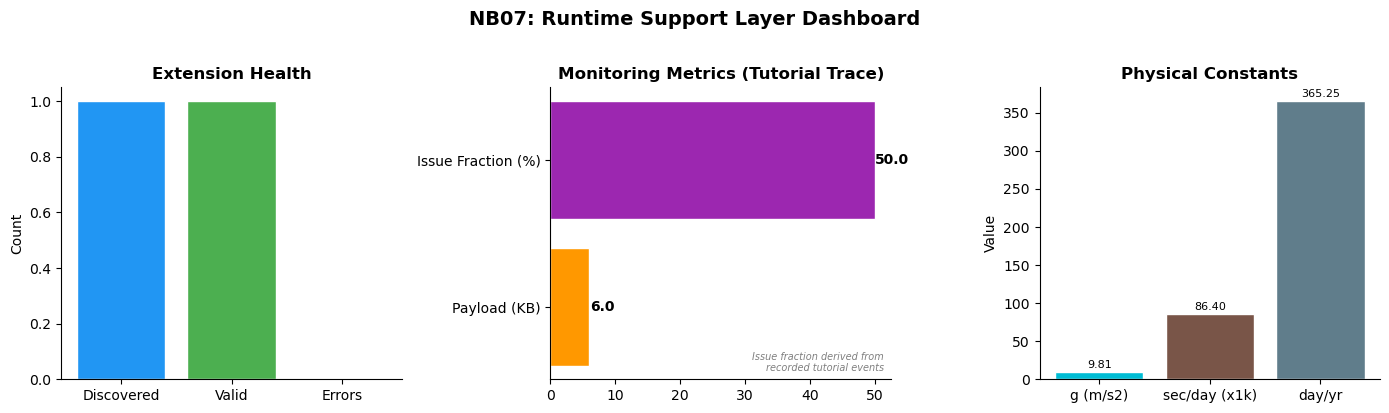

In [9]:
import matplotlib.pyplot as plt

# References:
#   RELIC extensions: relic/extensions/ (discovery.py, validator.py)
#   RELIC monitoring: relic/monitoring/prometheus.py
# Mathematical expression:
#   validation_pass_rate = valid_extensions / total_extensions
#   issue_fraction = n_issue_events / max(1, n_total_recorded_events)
# Parameter meanings:
#   monitoring_payload_bytes: UTF-8 size of the exported Prometheus payload [bytes]
#   extension_discovered_count: number of discovered RELIC extensions
#   monitoring_issue_fraction: fraction derived from recorded tutorial monitoring events

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Panel 1: Extension Health
ext_labels = ['Discovered', 'Valid', 'Errors']
ext_values = [
    summary['extension_discovered_count'],
    1 if summary['extension_validation_probe']['valid'] else 0,
    summary['extension_validation_probe']['error_count'],
]
ext_colors = ['#2196F3', '#4CAF50', '#f44336']
axes[0].bar(ext_labels, ext_values, color=ext_colors, edgecolor='white')
axes[0].set_title('Extension Health', fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# Panel 2: Monitoring Metrics
mon_labels = ['Payload (KB)', 'Issue Fraction (%)']
mon_values = [
    summary['monitoring_payload_bytes'] / 1024,
    summary['monitoring_issue_fraction'] * 100,
]
mon_colors = ['#FF9800', '#9C27B0']
axes[1].barh(mon_labels, mon_values, color=mon_colors, edgecolor='white')
axes[1].set_title('Monitoring Metrics (Tutorial Trace)', fontweight='bold')
axes[1].text(
    0.98,
    0.02,
    'Issue fraction derived from\nrecorded tutorial events',
    transform=axes[1].transAxes,
    ha='right',
    va='bottom',
    fontsize=7,
    fontstyle='italic',
    color='gray',
)
for i, value in enumerate(mon_values):
    axes[1].text(value + 0.1, i, f'{value:.1f}', va='center', fontweight='bold')
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

# Panel 3: Physical Constants Verification
const_labels = ['g (m/s2)', 'sec/day (x1k)', 'day/yr']
const_values = [
    summary['gravity_acceleration'],
    summary['seconds_per_day'] / 1000,
    summary['days_per_year'],
]
axes[2].bar(const_labels, const_values, color=['#00BCD4', '#795548', '#607D8B'], edgecolor='white')
axes[2].set_title('Physical Constants', fontweight='bold')
axes[2].set_ylabel('Value')
for i, value in enumerate(const_values):
    axes[2].text(i, value + 5, f'{value:.2f}', ha='center', fontsize=8)
axes[2].spines['top'].set_visible(False)
axes[2].spines['right'].set_visible(False)

fig.suptitle('NB07: Runtime Support Layer Dashboard', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## Summary

This notebook covered the runtime support layer:
- `relic.extensions`: scaffold, discovery and validation of a user extension
- `relic.monitoring`: Prometheus counters and the latency histogram of the REST API
- `relic.utils`: physical constants from `constants.yaml` and time constants from the parameter database
- `relic.core`: the three device tiers, the feature flags and the service registry

**Next:** Proceed to **NB08** for orchestration and data pipeline APIs.